In [1]:
import sys
from pathlib import Path
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# This makes it so this notebook file can access python files in ../src/
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

# And then we can import our functions
from src.config import load_yaml_config
from src.data import download_data, load_data_from_json
from src.plotting import set_plot_style, plot_R_m, plot_C_24, plot_city_comparison
from src.preprocessing import prepare_city_stream

config = load_yaml_config(project_root / "config.yaml")
city = "Porto"

In [2]:
# Download data if it isn't already downloaded
download_data(config["data"], city)

HTTP status: 200
Request URL: https://archive-api.open-meteo.com/v1/archive?latitude=41.1579&longitude=-8.6291&start_date=2020-01-01&end_date=2025-12-31&hourly=temperature_2m%2Crelative_humidity_2m%2Cprecipitation%2Cwind_speed_10m&timezone=Europe%2FLisbon


In [2]:
# Load the data from the downloaded json
df = load_data_from_json(config["data"], city)

In [3]:
display(df)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2020-01-01 00:00:00,5.4,99,0.0,6.2
1,2020-01-01 01:00:00,5.7,99,0.0,8.9
2,2020-01-01 02:00:00,5.5,98,0.0,10.0
3,2020-01-01 03:00:00,5.5,95,0.0,10.9
4,2020-01-01 04:00:00,5.1,94,0.0,10.1
...,...,...,...,...,...
52603,2025-12-31 19:00:00,9.0,73,0.0,11.7
52604,2025-12-31 20:00:00,7.7,77,0.0,13.5
52605,2025-12-31 21:00:00,7.3,78,0.0,14.7
52606,2025-12-31 22:00:00,7.1,78,0.0,15.7


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52608 entries, 0 to 52607
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  52608 non-null  datetime64[us]
 1   temperature_2m        52608 non-null  float64       
 2   relative_humidity_2m  52608 non-null  int64         
 3   precipitation         52608 non-null  float64       
 4   wind_speed_10m        52608 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 2.0 MB


In [5]:
# Check the percentage of missing values for each column:
round(df.isna().sum() / len(df) * 100, 2)

time                    0.0
temperature_2m          0.0
relative_humidity_2m    0.0
precipitation           0.0
wind_speed_10m          0.0
dtype: float64

In [6]:
# Check basic duplicated data
df.duplicated().sum()

np.int64(0)

In [7]:
# Create the rain event
df["rain_event"] = (df["precipitation"] >= 0.1).astype(int)

In [9]:
df["rain_event"].value_counts()

rain_event
0    41881
1    10727
Name: count, dtype: int64

In [10]:
df["rain_event"].value_counts(normalize=True)

rain_event
0    0.796096
1    0.203904
Name: proportion, dtype: float64

In [10]:
# Descriptive statistics
df.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rain_event
count,52608,52608.000000,52608.000000,52608.00000,52608.000000,52608.000000
mean,2022-12-31 23:30:00,15.523162,78.726505,0.16629,13.006834,0.203904
min,2020-01-01 00:00:00,0.000000,12.000000,0.00000,0.000000,0.000000
25%,2021-07-01 23:45:00,12.300000,69.000000,0.00000,7.300000,0.000000
50%,2022-12-31 23:30:00,15.400000,81.000000,0.00000,11.900000,0.000000
75%,2024-07-01 23:15:00,18.500000,91.000000,0.00000,17.300000,0.000000
90%,2025-05-26 18:18:00,21.700000,96.000000,0.30000,23.100000,1.000000
95%,2025-09-13 08:39:00,23.700000,97.000000,0.90000,26.800000,1.000000
99%,2025-12-10 00:55:48,28.200000,100.000000,3.30000,34.300000,1.000000
max,2025-12-31 23:00:00,36.400000,100.000000,21.50000,55.200000,1.000000


In [11]:
def check_hourly_continuity(df):
    timestamps = (
        pd.to_datetime(df["time"])
        .sort_values()
        .reset_index(drop=True)
    )

    differences = timestamps.diff()

    irregular = differences[
        differences.notna() &
        (differences != pd.Timedelta(hours=1))
    ]

    print(f"Number of observations: {len(timestamps)}")
    print(f"Duplicate timestamps: {timestamps.duplicated().sum()}")
    print(f"Non-hourly transitions: {len(irregular)}")

    if irregular.empty:
        print("The stream is continuous at hourly intervals.")
    else:
        print("\nIrregular transitions:")
        for i in irregular.index:
            print(
                f"{timestamps.iloc[i-1]} -> "
                f"{timestamps.iloc[i]} "
                f"({differences.iloc[i]})"
            )

    return irregular

check_hourly_continuity(df)

Number of observations: 52608
Duplicate timestamps: 0
Non-hourly transitions: 0
The stream is continuous at hourly intervals.


Series([], Name: time, dtype: timedelta64[us])

In [9]:
plot_R_m(config["plotting"], df, city)

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Porto_R_m_f434yqpp.pdf


In [11]:
plot_C_24(config["plotting"], df, city)

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\Porto_C_24_74m9383f.pdf


In [8]:
lisboa_df = load_data_from_json(config["data"], "Lisboa")
lisboa_df["rain_event"] = (lisboa_df["precipitation"] >= 0.1).astype(int)
plot_city_comparison(config["plotting"], lisboa_df, df)

Saved B:\Documents\Uni\Data Stream Mining\Assignments\Practical Assignment 1\temp\city_comparison_zpkcntxz.pdf


In [10]:
rainy = df[df["rain_event"] == 1]

proportion_rain_above_50_humidity = (
    rainy["relative_humidity_2m"] >= 50
).mean()

print(proportion_rain_above_50_humidity)

0.9988813274913769


In [36]:
c24 = df["rainy_hours_previous_24h"].dropna()

print("Mean:", c24.mean())
print("Median:", c24.median())
print("90th percentile:", c24.quantile(0.90, interpolation="higher"))
print("95th percentile:", c24.quantile(0.95, interpolation="higher"))
print("Maximum:", c24.max())

print("Proportion <= 17:", (c24 <= 17).mean())
print("Proportion >= 17:", (c24 >= 17).mean())

print(df["rain_event"].mean())
print(c24.mean() / 24)

Mean: 4.89593792788681
Median: 0.0
90th percentile: 17.0
95th percentile: 21.0
Maximum: 24.0
Proportion <= 17: 0.9048950251026928
Proportion >= 17: 0.11020462498098281
0.20390434914841848
0.20399741366195043


# Ignore this stuff:

17.0


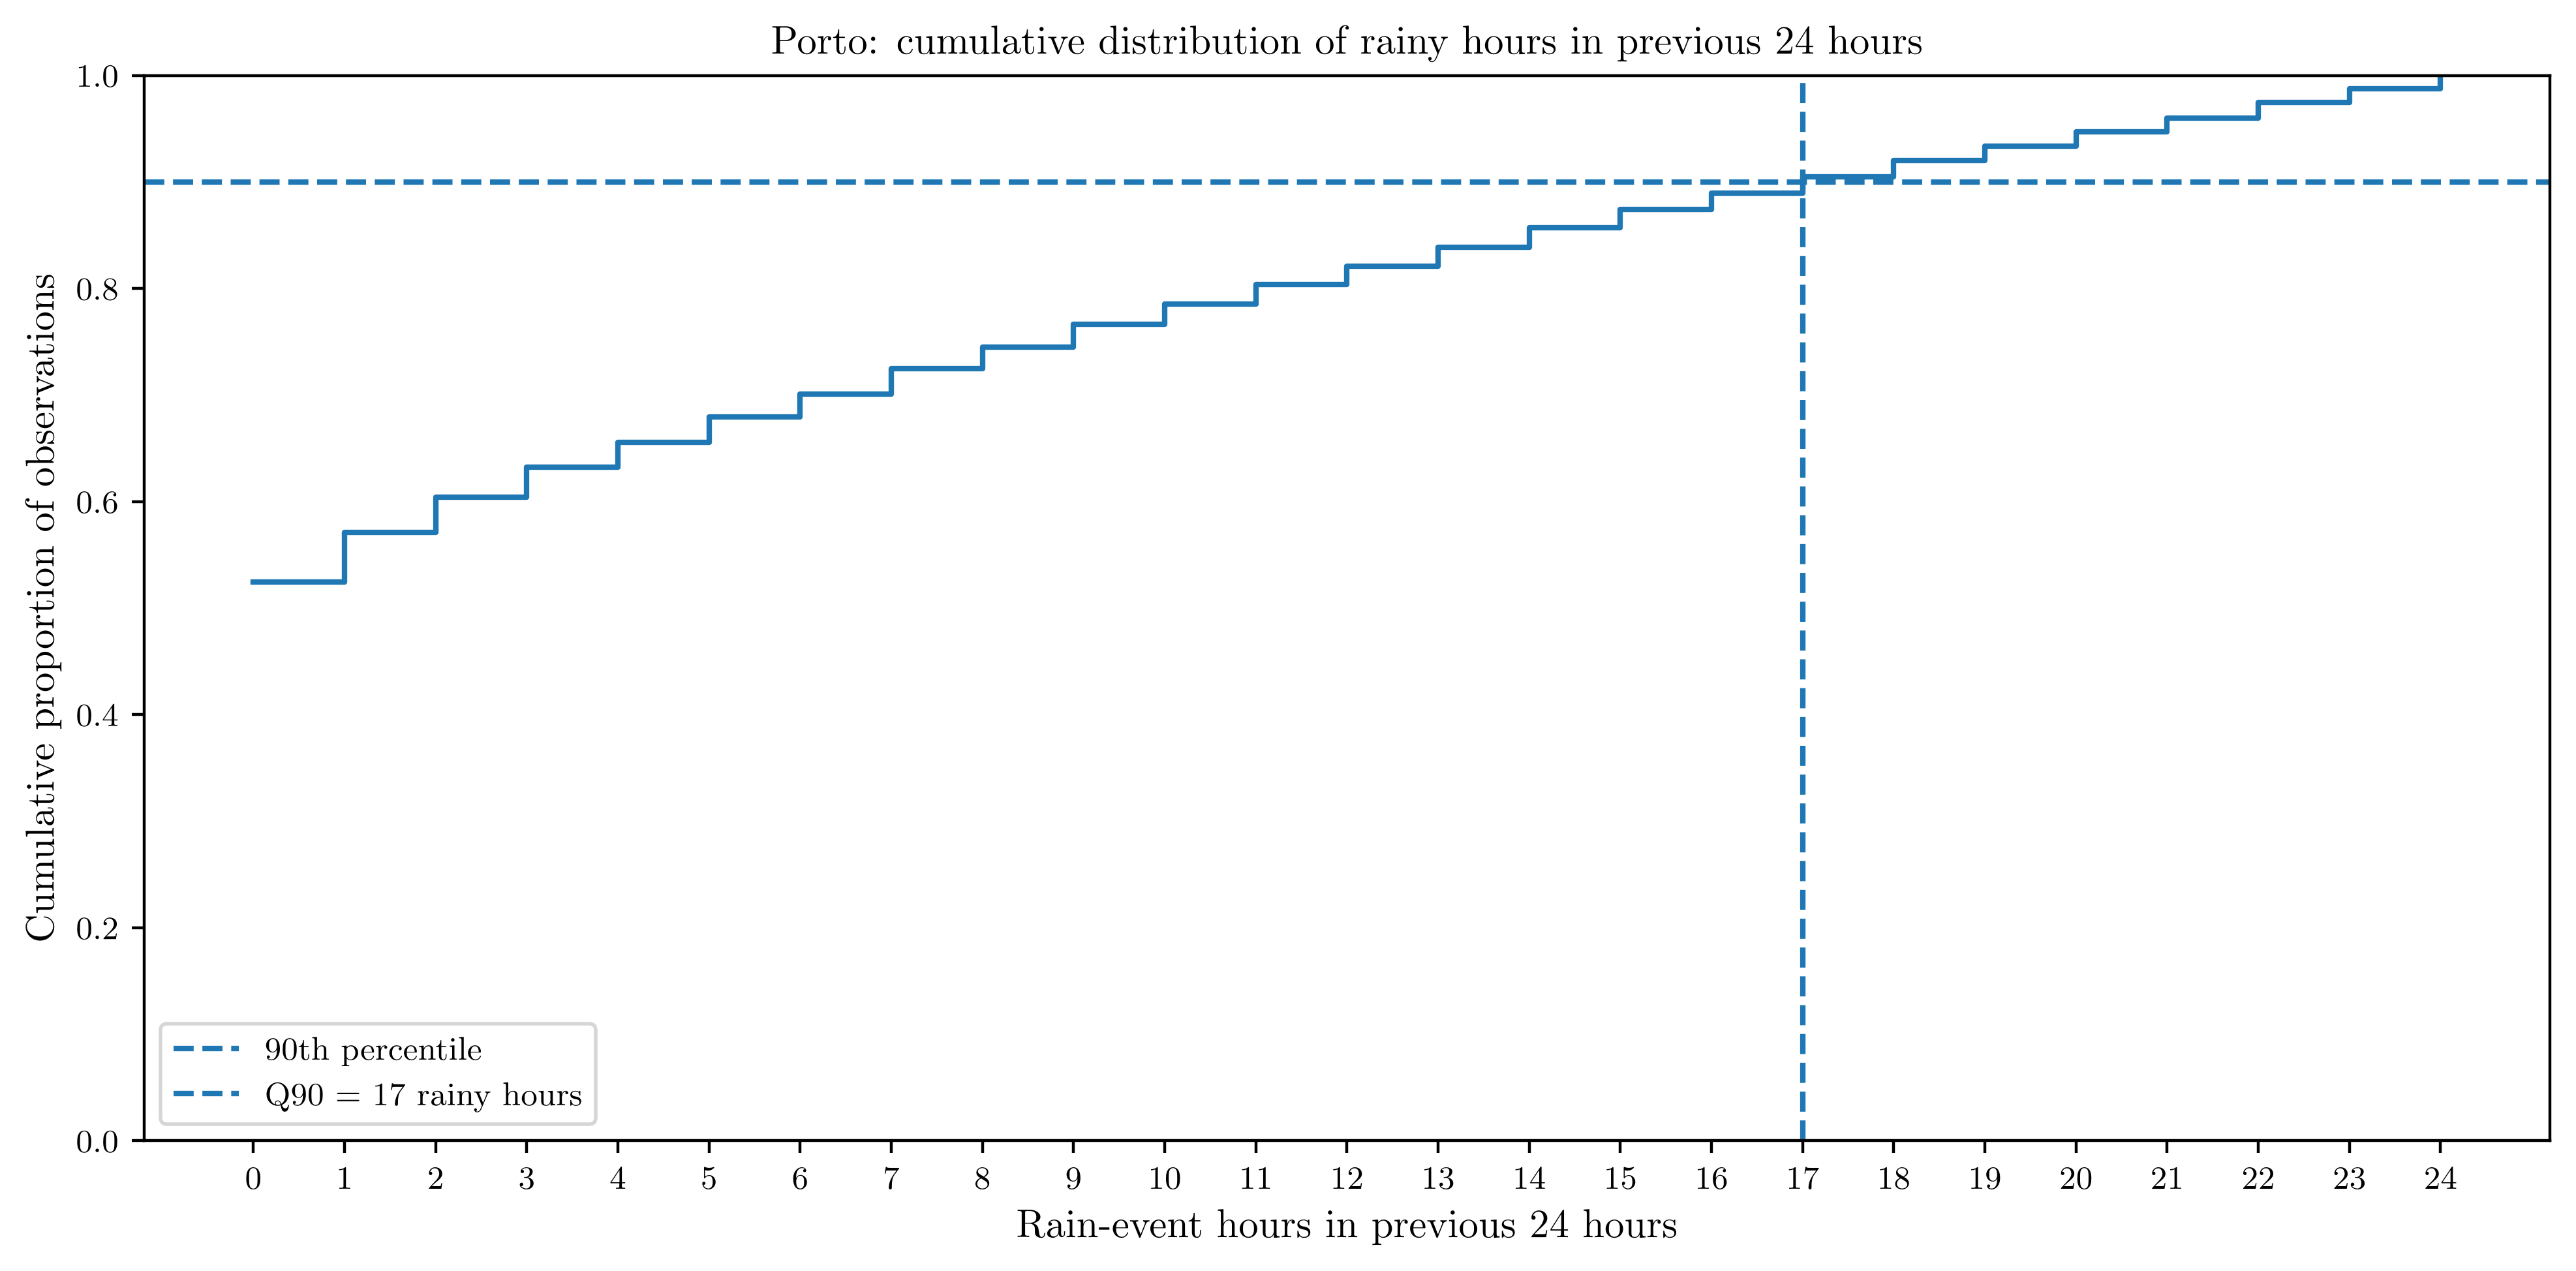

In [12]:
c24 = df["rainy_hours_previous_24h"].dropna()

# Frequency of each possible value: 0, 1, ..., 24
counts = c24.value_counts().sort_index()

# Cumulative proportion
cdf = counts.cumsum() / counts.sum()

# 90th percentile
q90 = c24.quantile(0.90, interpolation="higher")
print(q90)

plt.figure(figsize=(10, 5))

plt.step(
    cdf.index,
    cdf.values,
    where="post"
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90th percentile"
)

plt.axvline(
    q90,
    linestyle="--",
    label=f"Q90 = {q90:.0f} rainy hours"
)

plt.xlabel("Rain-event hours in previous 24 hours")
plt.ylabel("Cumulative proportion of observations")
plt.title("Porto: cumulative distribution of rainy hours in previous 24 hours")

plt.xticks(range(0, 25))
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
run_id = df["rain_event"].ne(df["rain_event"].shift()).cumsum()

rain_runs = (
    df.loc[df["rain_event"].eq(1)]
      .groupby(run_id)
      .size()
)

print(rain_runs.describe())
print("Longest consecutive rain-event run:", rain_runs.max(), "hours")

count    1967.000000
mean        5.453482
std         6.976399
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max        58.000000
dtype: float64
Longest consecutive rain-event run: 58 hours


<Figure size 1000x600 with 0 Axes>

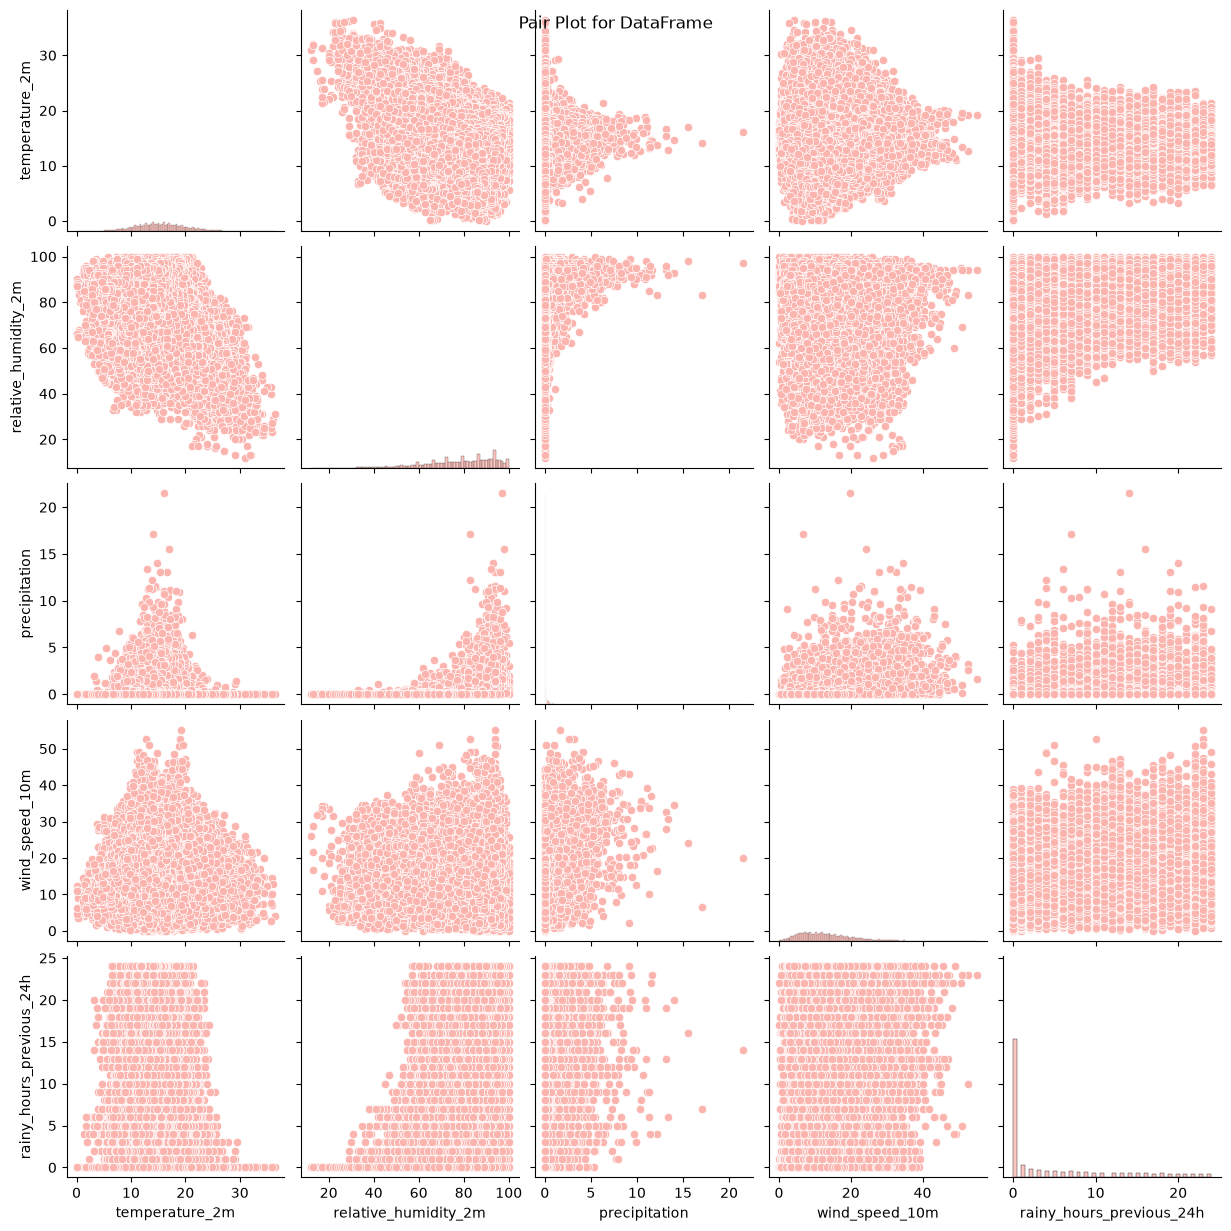

In [15]:
import seaborn as sns

df_new = df.drop("rain_event", axis=1)
sns.set_palette("Pastel1")

plt.figure(figsize=(10, 6))

sns.pairplot(df_new)

plt.suptitle('Pair Plot for DataFrame')
plt.show()

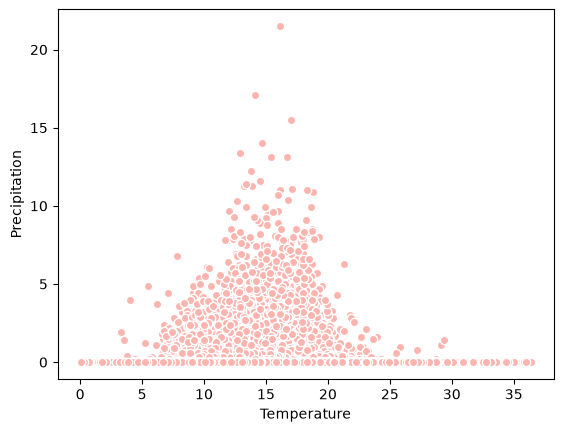

In [23]:
plt.scatter(df_new["temperature_2m"], df_new["precipitation"], edgecolors="white")
plt.xlabel("Temperature")
plt.ylabel("Precipitation")
plt.show()

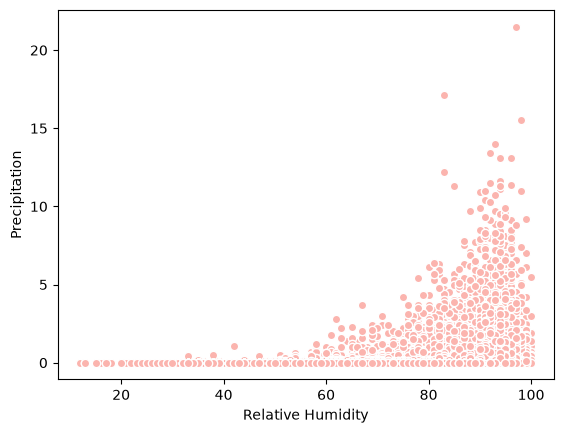

In [24]:
plt.scatter(df_new["relative_humidity_2m"], df_new["precipitation"], edgecolors="white")
plt.xlabel("Relative Humidity")
plt.ylabel("Precipitation")
plt.show()

In [55]:
df_new.loc[df["relative_humidity_2m"] < 50].describe(percentiles=[0.9, 0.95, 0.99, 0.999])

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,rainy_hours_previous_24h
count,2323,2323.000000,2323.000000,2323.000000,2323.000000,2323.000000
mean,2023-02-10 18:31:39.956952,21.528885,41.908739,0.001464,16.249505,0.194146
min,2020-01-20 13:00:00,4.500000,12.000000,0.000000,0.400000,0.000000
90%,2025-07-29 17:48:00,29.600000,48.000000,0.000000,26.600000,0.000000
95%,2025-09-23 10:54:00,31.200000,49.000000,0.000000,28.800000,1.000000
99%,2025-10-11 17:33:36,33.278000,49.000000,0.000000,33.434000,5.000000
99.9%,2025-10-27 14:40:40.800000,36.000000,49.000000,0.400000,35.203400,9.678000
max,2025-11-20 16:00:00,36.400000,49.000000,1.100000,37.200000,11.000000
std,NaN,6.532898,6.365506,0.028718,7.304875,0.959885


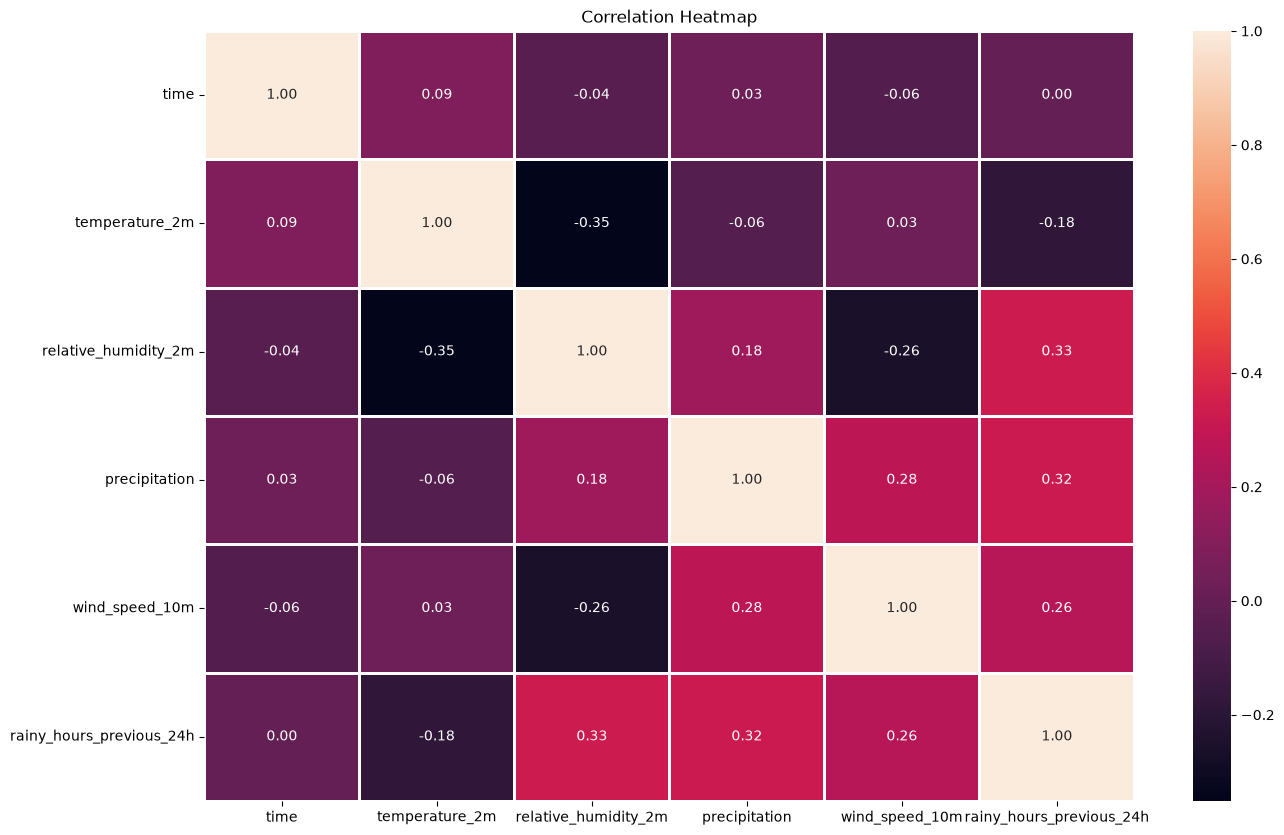

In [17]:
plt.figure(figsize=(15, 10))

sns.heatmap(df_new.corr(), annot=True, fmt='.2f', linewidths=2)

plt.title('Correlation Heatmap')
plt.show()

In [27]:
df["rainy_hours_previous_24h"].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95]
)

count    52584.000000
mean         4.895938
std          7.051724
min          0.000000
50%          0.000000
75%          9.000000
90%         17.000000
95%         21.000000
max         24.000000
Name: rainy_hours_previous_24h, dtype: float64

In [28]:
df["rainy_hours_previous_24h"].median()

np.float64(0.0)

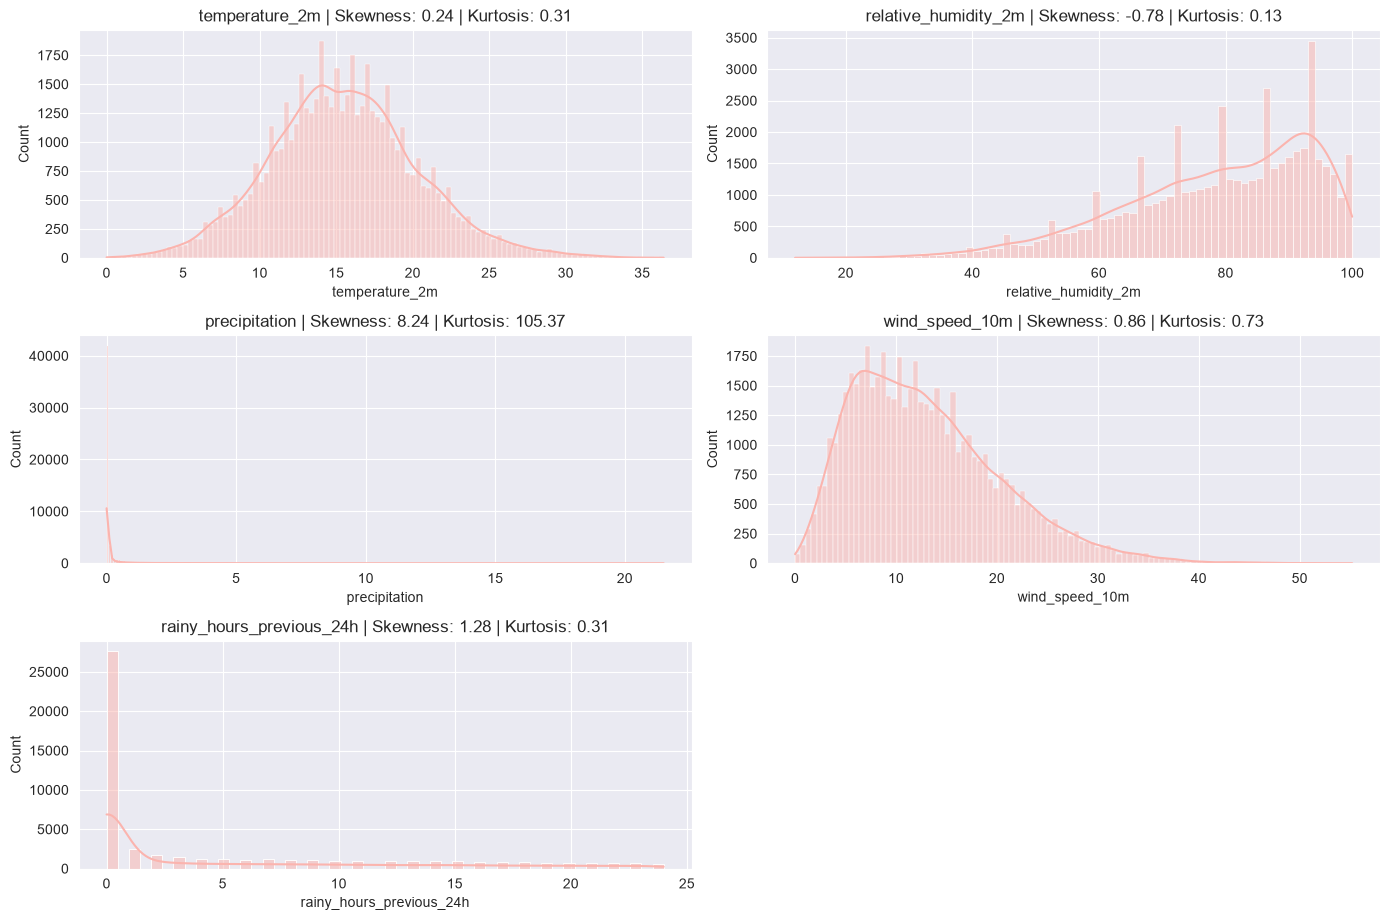

In [57]:
sns.set_style("darkgrid")

numerical_columns = df_new.select_dtypes(include=["int64", "float64"]).columns

plt.figure(figsize=(14, len(numerical_columns) * 3))
for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(len(numerical_columns), 2, idx)
    sns.histplot(df_new[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df_new[feature].skew(), 2)} | Kurtosis: {round(df_new[feature].kurtosis(), 2)}")

plt.tight_layout()
plt.show()